# CIS*4020 — Assignment 2 Starter Notebook
## Eager vs. Lazy Learning: Decision Trees & k-NN on OULAD

This is a **scaffold** — not the solution.

- Cells marked **PROVIDED** run as-is (data loading, the analysis table, and a few helpers).
- Cells marked **# TODO** are yours to complete.
- This notebook **is** your report: put narrative in markdown cells and code in code cells, and make it run top-to-bottom.
- Rename it **`a2_lastname.ipynb`** before submitting.

**Data:** download OULAD data and point `DATA_DIR` at the CSVs
(`https://archive.ics.uci.edu/dataset/349/open+university+learning+analytics+dataset`).

## Setup  *(PROVIDED)*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 40)
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.1.0 | scikit-learn 1.9.1


## Data loading  *(PROVIDED, same loader as Assignment 1)*

Loads the real OULAD CSVs from `DATA_DIR` if present.

In [2]:
DATA_DIR = "content/"   # folder containing the OULAD .csv files (relative to this notebook)

FILES = {"studentInfo":"studentInfo.csv", "studentRegistration":"studentRegistration.csv",
         "studentVle":"studentVle.csv", "vle":"vle.csv", "assessments":"assessments.csv",
         "studentAssessment":"studentAssessment.csv", "courses":"courses.csv"}

def load_oulad():
    missing = [f for f in FILES.values() if not os.path.exists(os.path.join(DATA_DIR, f))]
    if missing:
        raise FileNotFoundError(
            f"Couldn't find these OULAD files in DATA_DIR={DATA_DIR!r}: {missing}. "
            "Set DATA_DIR to the folder containing the CSVs."
        )
    print("[info] loading real OULAD from", DATA_DIR)
    return {k: pd.read_csv(os.path.join(DATA_DIR, f), na_values="?") for k, f in FILES.items()}

tables = load_oulad()
for name, t in tables.items():
    print(f"{name:22s} {t.shape}")

[info] loading real OULAD from content/


studentInfo            (32593, 12)
studentRegistration    (32593, 5)
studentVle             (10655280, 6)
vle                    (6364, 6)
assessments            (206, 6)
studentAssessment      (173912, 5)
courses                (22, 3)


## Build the analysis table  *(PROVIDED, mirrors Assignment 1)*

Aggregates the clickstream to one row per student-module and joins it to the student table. You may
replace this with your own Assignment 1 cleaning code.

In [3]:
KEYS = ["code_module", "code_presentation", "id_student"]
CUTOFF_DAY = 30      # prediction point: only information from before this day may be a feature

vle = tables["studentVle"]

# Early engagement: the only clickstream features the models are allowed to see.
early = (vle[vle["date"] < CUTOFF_DAY]
         .groupby(KEYS)
         .agg(early_clicks=("sum_click", "sum"), early_active_days=("date", "nunique"))
         .reset_index())

# Whole-course engagement: kept ONLY for the leakage comparison at the end of the notebook.
whole_course = (vle.groupby(KEYS)
                .agg(total_clicks=("sum_click", "sum"), active_days=("date", "nunique"))
                .reset_index())

analysis = (tables["studentInfo"]
            .merge(tables["studentRegistration"], on=KEYS, how="left")
            .merge(early, on=KEYS, how="left")
            .merge(whole_course, on=KEYS, how="left"))

# No clickstream rows in the window means zero recorded clicks, not an unknown value.
for c in ["early_clicks", "early_active_days", "total_clicks", "active_days"]:
    analysis[c] = analysis[c].fillna(0)

analysis["imd_band"] = analysis["imd_band"].replace({"10-20": "10-20%"})   # known formatting quirk (A1)

print("analysis table:", analysis.shape)
assert not analysis.duplicated(KEYS).any()      # one row per student-module
analysis.head()

analysis table: (32593, 18)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,date_registration,date_unregistration,early_clicks,early_active_days,total_clicks,active_days
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,-159.0,NaN,419.0,9.0,934.0,40.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,-53.0,NaN,618.0,19.0,1435.0,80.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,-92.0,12.0,281.0,12.0,281.0,12.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,-52.0,NaN,503.0,23.0,2158.0,123.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,-176.0,NaN,567.0,24.0,1034.0,70.0


In [4]:
# Who is actually predictable at day 30?
left_before_cutoff = analysis["date_unregistration"] < CUTOFF_DAY
registered_after_cutoff = analysis["date_registration"] >= CUTOFF_DAY

print("all student-module rows:            ", len(analysis))
print("unregistered before the cutoff:     ", int(left_before_cutoff.sum()))
print("registered on/after the cutoff:     ", int(registered_after_cutoff.sum()))
print("\noutcomes of students who left before the cutoff:")
print(analysis.loc[left_before_cutoff, "final_result"].value_counts().to_string())

df = analysis[~left_before_cutoff & ~registered_after_cutoff].copy()
print("\nmodelling population:               ", len(df))

all student-module rows:             32593
unregistered before the cutoff:      5067
registered on/after the cutoff:      16

outcomes of students who left before the cutoff:
final_result
Withdrawn    5059
Fail            8

modelling population:                27510


**TODO (markdown):** Explain the changes you made to the provided data loading and analysis table: which features are known at your prediction point, and which students you kept.
**Data Loading** 
My assignment 1 loader was used with na_values = "?", as OULAD marks missing values with "?". The starter's download cell and synthetic fallback was removed so a missing file raises an error.

**Features** 
The features that were kept: early_clicks and early_active_days, as well as student and registration details.
The features that were removed: total_clicks, id_student, code presentation, and date unregistration(reveals withdrawal).

**Students**
There were 5067 students who unregistered before day 30, so they were removed as the outcome was already known, as well as 16 students who registered after day 30.

## pandas / scikit-learn quick reference

| Task | Code |
|---|---|
| stratified holdout split | `train_test_split(X, y, test_size=.2, stratify=y, random_state=42)` |
| one-hot + scale together | `ColumnTransformer([...])` |
| model = preprocess + classifier | `Pipeline([("prep", pre), ("clf", clf)])` |
| 5-fold CV score | `cross_val_score(model, X, y, cv=StratifiedKFold(5))` |
| metrics | `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` |
| decision-tree importance | `model.named_steps["clf"].feature_importances_` |
| k-NN importance | `permutation_importance(model, X_test, y_test)` |

## An evaluation helper  *(PROVIDED)*

Prints the confusion matrix and the binary metrics for the positive class.

In [5]:
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)
def evaluate(model, name):
    """Fit on the training set, then report the confusion matrix and metrics on the test set."""
    model.fit(X_tr, y_tr); pred = model.predict(X_te)
    cm = confusion_matrix(y_te, pred)
    row = {"model": name,
           "accuracy": accuracy_score(y_te, pred),
           "precision": precision_score(y_te, pred, zero_division=0),
           "recall": recall_score(y_te, pred, zero_division=0),
           "f1": f1_score(y_te, pred, zero_division=0)}
    print(f"=== {name} ===")
    print("confusion matrix [rows=actual 0/1, cols=pred 0/1]:")
    print(cm)
    print(f"accuracy  = {row['accuracy']:.3f}")
    print(f"precision = {row['precision']:.3f}   (positive class = at risk)")
    print(f"recall    = {row['recall']:.3f}")
    print(f"f1        = {row['f1']:.3f}\n")
    return row, cm
print("helper ready")

helper ready


## Part 1 — Exploration

In [ ]:
# Part 1: define your classification task and create the target variable.
AT_RISK = ["Fail", "Withdrawn"]
df["at_risk"] = df["final_result"].isin(AT_RISK).astype(int)

print(pd.crosstab(df["final_result"], df["at_risk"]).to_string())

at_risk           0     1
final_result             
Distinction    3023     0
Fail              0  7037
Pass          12356     0
Withdrawn         0  5094


**TODO (markdown):** State your classification task and target variable.

Task: predict on day 30 which students are at risk of failing or withdrawing using only what is known by then.

Target: at_risk = 1 for fail or withdrawn, at_risk = 0 for pass or distinction.

,students,share
"0 = not at risk (Pass, Distinction)",15379,0.559
"1 = at risk (Fail, Withdrawn)",12131,0.441


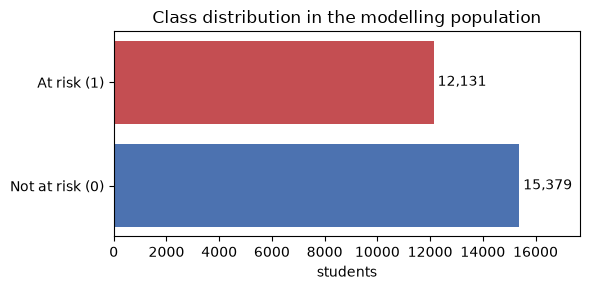

In [ ]:
# Part 1: class distribution (is it balanced?)
counts = df["at_risk"].value_counts().sort_index()
class_table = pd.DataFrame({"students": counts, "share": (counts / counts.sum()).round(3)})
class_table.index = ["0 = not at risk (Pass, Distinction)", "1 = at risk (Fail, Withdrawn)"]
display(class_table)

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(["Not at risk (0)", "At risk (1)"], counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_title("Class distribution in the modelling population")
ax.set_xlabel("students"); ax.set_xlim(0, counts.max() * 1.15)
plt.tight_layout(); plt.show()

**TODO (markdown):** Describe the class distribution and note any imbalance.

12,131 students are at risk, 15,379 are not. This is a mild imbalance so I didn't resample. Always predicting not at risk would still get 55.9% accuracy, so results are compared against baselines.

In [ ]:
# Part 1: feature types. Which columns are numeric vs categorical?
LOG_NUMERIC = ["early_clicks"]
NUMERIC     = ["early_active_days", "date_registration", "num_of_prev_attempts", "studied_credits"]
ORDINAL     = ["highest_education", "imd_band", "age_band"]
NOMINAL     = ["code_module", "gender", "region", "disability"]
FEATURES    = LOG_NUMERIC + NUMERIC + ORDINAL + NOMINAL

LEAKY_OR_ID = ["total_clicks", "active_days", "date_unregistration", "final_result",
               "at_risk", "id_student", "code_presentation"]
assert not set(FEATURES) & set(LEAKY_OR_ID)     # no leaked column or identifier can reach a model

feature_types = pd.DataFrame({
    "feature": FEATURES,
    "kind": ["numeric"] * 5 + ["categorical (ordinal)"] * 3 + ["categorical (nominal)"] * 4,
    "pandas dtype": [str(df[c].dtype) for c in FEATURES],
    "distinct values": [df[c].nunique() for c in FEATURES],
    "missing": [int(df[c].isna().sum()) for c in FEATURES],
})
display(feature_types)

,feature,kind,pandas dtype,distinct values,missing
0,early_clicks,numeric,float64,1982,0
1,early_active_days,numeric,float64,56,0
2,date_registration,numeric,float64,301,7
3,num_of_prev_attempts,numeric,int64,7,0
4,studied_credits,numeric,int64,51,0
5,highest_education,categorical (ordinal),str,5,0
6,imd_band,categorical (ordinal),str,10,1027
7,age_band,categorical (ordinal),str,3,0
8,code_module,categorical (nominal),str,7,0
9,gender,categorical (nominal),str,2,0


**TODO (markdown):** Describe the feature types.

Numeric: early_clicks, early_active_days, date_registration, num_of_prev_attempts, studied_credits

Ordinal: highest_education, imd_band, age_band

Nominal: code_module, gender, region, disability

In [ ]:
# Part 1: value distributions BY CLASS for the numeric features.
NUMERIC_ALL = LOG_NUMERIC + NUMERIC
print("summary by class:")
display(df.groupby("at_risk")[NUMERIC_ALL].agg(["median", "mean"]).round(1).T)
print("skewness:")
print(df[NUMERIC_ALL].skew().round(2).to_string())
print("\nskewness after log1p (kept only where it helps):")
print(np.log1p(df[["early_clicks", "early_active_days"]]).skew().round(2).to_string())

summary by class:


at_risk                          0      1
early_clicks         median  305.0  155.0
                     mean    451.0  255.6
early_active_days    median   16.0   10.0
                     mean     17.6   11.7
date_registration    median  -53.0  -53.0
                     mean    -66.5  -66.4
num_of_prev_attempts median    0.0    0.0
                     mean      0.1    0.2
studied_credits      median   60.0   60.0
                     mean     73.7   79.6

skewness:
early_clicks            3.47
early_active_days       0.77
date_registration      -1.04
num_of_prev_attempts    3.83
studied_credits         1.75

skewness after log1p (kept only where it helps):
early_clicks        -1.37
early_active_days   -0.95


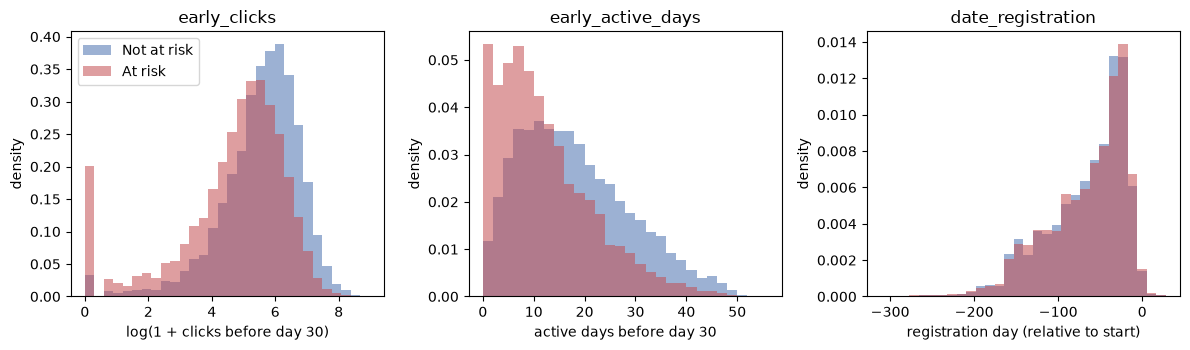

In [ ]:
LABELS = {0: "Not at risk", 1: "At risk"}
COLOURS = {0: "#4C72B0", 1: "#C44E52"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
plots = [("early_clicks", np.log1p(df["early_clicks"]), "log(1 + clicks before day 30)"),
         ("early_active_days", df["early_active_days"], "active days before day 30"),
         ("date_registration", df["date_registration"], "registration day (relative to start)")]
for ax, (name, values, xlabel) in zip(axes, plots):
    bins = np.arange(0, values.max() + 3, 2) if name == "early_active_days" else np.histogram_bin_edges(values.dropna(), bins=30)
    for cls in [0, 1]:
        ax.hist(values[df["at_risk"] == cls], bins=bins, density=True, alpha=0.55,
                color=COLOURS[cls], label=LABELS[cls])
    ax.set_title(name); ax.set_xlabel(xlabel); ax.set_ylabel("density")
axes[0].legend()
plt.tight_layout(); plt.show()

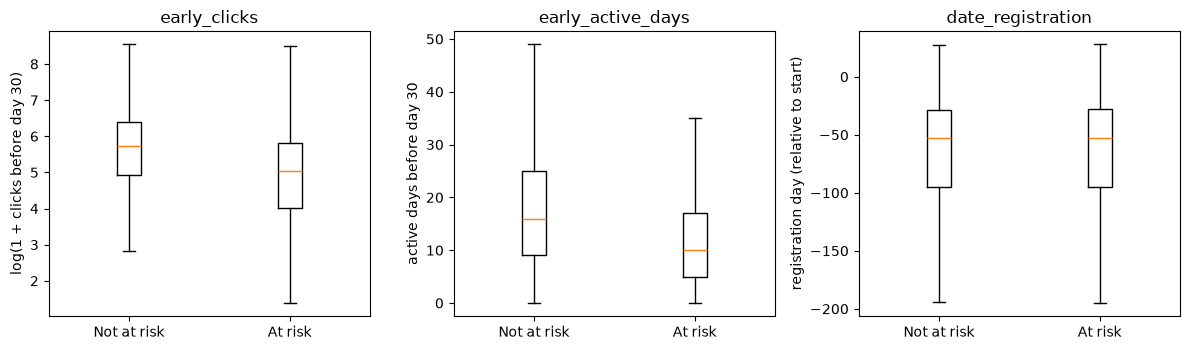

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, values, ylabel) in zip(axes, plots):
    groups = [values[df["at_risk"] == cls].dropna() for cls in [0, 1]]
    ax.boxplot(groups, tick_labels=[LABELS[0], LABELS[1]], showfliers=False)
    ax.set_title(name); ax.set_ylabel(ylabel)
plt.tight_layout(); plt.show()

num_of_prev_attempts
                       mean   size
num_of_prev_attempts              
0                     0.418  24044
1                     0.588   2761
2                     0.655    550
3+                    0.690    155

studied_credits
                  mean   size
studied_credits              
<=30             0.406   3554
31-60            0.421  14746
61-90            0.472   2794
91-120           0.472   4860
>120             0.562   1556



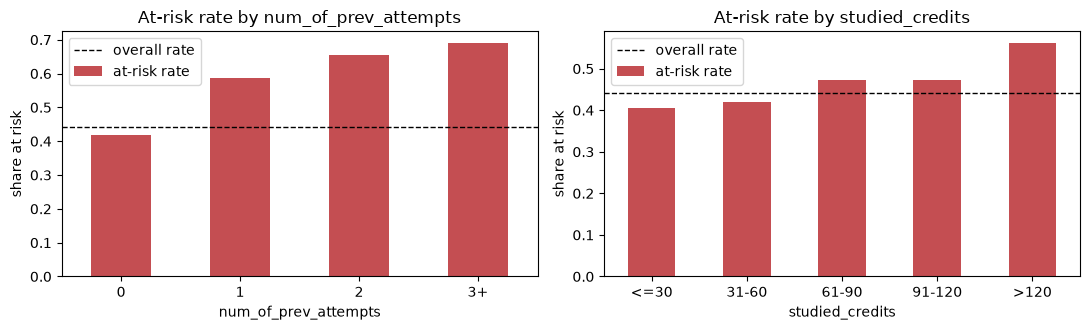

In [ ]:
# The two discrete numerics read better as at-risk rates than as histograms.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col in zip(axes, ["num_of_prev_attempts", "studied_credits"]):
    binned = df[col].clip(upper=3).astype(str).replace({"3": "3+"}) if col == "num_of_prev_attempts" else pd.cut(
        df[col], [0, 30, 60, 90, 120, 700], labels=["<=30", "31-60", "61-90", "91-120", ">120"])
    rate = df.groupby(binned, observed=True)["at_risk"].agg(["mean", "size"])
    rate["mean"].plot(kind="bar", ax=ax, color="#C44E52", label="at-risk rate")
    ax.axhline(df["at_risk"].mean(), color="k", ls="--", lw=1, label="overall rate")
    ax.set_title(f"At-risk rate by {col}"); ax.set_ylabel("share at risk"); ax.tick_params(axis="x", rotation=0)
    ax.legend()
    print(col); print(rate.round(3).to_string()); print()
plt.tight_layout(); plt.show()

**TODO (markdown):** Describe what the value distributions show for each class.

Early engagement seperates the 2 classes. Mean early_clicks is 451 for not at risk students, while the mean is 255 for at risk students.

date_registration barely differs between the 2 classes. However with prior attempts, the at-risk rate goes from 41.8% with none to 69% with 3 or more attempts.

Students who studied 30 or less credits sit with an at-risk rate of 40.6%, with students studying over 120 credits sit at 56.2%.


In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

EDU_ORDER = ["No Formal quals", "Lower Than A Level", "A Level or Equivalent",
             "HE Qualification", "Post Graduate Qualification"]
IMD_ORDER = ["0-10%", "10-20%", "20-30%", "30-40%", "40-50%", "50-60%", "60-70%", "70-80%", "80-90%", "90-100%"]
AGE_ORDER = ["0-35", "35-55", "55<="]

def build_preprocessor(log_numeric=LOG_NUMERIC, numeric=NUMERIC):
    log_numeric_steps = Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    ordinal_steps = Pipeline([
        ("encode", OrdinalEncoder(categories=[EDU_ORDER, IMD_ORDER, AGE_ORDER],
                                  handle_unknown="use_encoded_value", unknown_value=np.nan)),
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("log_num", log_numeric_steps, list(log_numeric)),
        ("num", numeric_steps, list(numeric)),
        ("ord", ordinal_steps, ORDINAL),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL),
    ])

def make_model(clf, preprocessor=None):
    """Preprocessing + classifier, so the transforms are re-learned on training data only."""
    return Pipeline([("prep", clone(preprocessor) if preprocessor is not None else build_preprocessor()),
                     ("clf", clf)])

**TODO (markdown):** Document your preprocessing decisions: how you encoded the categorical features and why, and why you scaled the numeric features.

Ordinal encoding for education, IMD and age becasue they have meaningful order. 

One-hot encoding for nominal features. Integer codes would invent an order, 33 columns from 12 features.

Missing imd_band: median plus a missing flag, keeps my A1 keep-and-flag decisions in numeric form.

log1p on early_clicks as it is very skewed (3.47, -1.37 after the transform).

Standardized numeric features (z-score) as k-NN uses distance so features with a large range would dominate otherwise.

In [ ]:
from sklearn.model_selection import StratifiedKFold, train_test_split

X = df[FEATURES]
y = df["at_risk"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_SEED)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

print("train:", X_tr.shape, "| at-risk share:", round(y_tr.mean(), 4))
print("test: ", X_te.shape, "| at-risk share:", round(y_te.mean(), 4))
for i, (fit_idx, val_idx) in enumerate(cv5.split(X_tr, y_tr), start=1):
    print(f"fold {i}: fit {len(fit_idx)}, validate {len(val_idx)}, "
          f"validation at-risk share {y_tr.iloc[val_idx].mean():.4f}")

train: (22008, 12) | at-risk share: 0.441
test:  (5502, 12) | at-risk share: 0.4409
fold 1: fit 17606, validate 4402, validation at-risk share 0.4409
fold 2: fit 17606, validate 4402, validation at-risk share 0.4409
fold 3: fit 17606, validate 4402, validation at-risk share 0.4409
fold 4: fit 17607, validate 4401, validation at-risk share 0.4410
fold 5: fit 17607, validate 4401, validation at-risk share 0.4410


In [ ]:
# Sanity check: fit the preprocessing on the training set only and inspect the result.
prep_check = build_preprocessor().fit(X_tr)
names = prep_check.get_feature_names_out()
Xt_tr = prep_check.transform(X_tr)
Xt_te = prep_check.transform(X_te)

print("columns before encoding:", X_tr.shape[1], "| after encoding:", Xt_tr.shape[1])
print("NaNs after preprocessing: train", int(np.isnan(Xt_tr).sum()), "| test", int(np.isnan(Xt_te).sum()))
scaled = pd.DataFrame(Xt_tr, columns=names).iloc[:, :9]
display(scaled.describe().loc[["mean", "std"]].round(3))
print("all columns:", list(names))

columns before encoding: 12 | after encoding: 33
NaNs after preprocessing: train 0 | test 0


,log_num__early_clicks,num__early_active_days,num__date_registration,num__num_of_prev_attempts,num__studied_credits,ord__highest_education,ord__imd_band,ord__age_band,ord__missingindicator_imd_band
mean,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


all columns: ['log_num__early_clicks', 'num__early_active_days', 'num__date_registration', 'num__num_of_prev_attempts', 'num__studied_credits', 'ord__highest_education', 'ord__imd_band', 'ord__age_band', 'ord__missingindicator_imd_band', 'nom__code_module_AAA', 'nom__code_module_BBB', 'nom__code_module_CCC', 'nom__code_module_DDD', 'nom__code_module_EEE', 'nom__code_module_FFF', 'nom__code_module_GGG', 'nom__gender_F', 'nom__gender_M', 'nom__region_East Anglian Region', 'nom__region_East Midlands Region', 'nom__region_Ireland', 'nom__region_London Region', 'nom__region_North Region', 'nom__region_North Western Region', 'nom__region_Scotland', 'nom__region_South East Region', 'nom__region_South Region', 'nom__region_South West Region', 'nom__region_Wales', 'nom__region_West Midlands Region', 'nom__region_Yorkshire Region', 'nom__disability_N', 'nom__disability_Y']


**TODO (markdown):** Explain your holdout and 5-fold cross-validation setup, and how preprocessing is fit on training data only.
Holdout: stratified 80/20 split (22,008 train, 5,502 test)

Cross validation: stratified 5-fold on the training set, which is also used for tuning.

No leakage: encoders, imputers and scalers sit inside a pipeline so they are fit on only the training part of each fold.

## Part 2 — Train the models

Use `make_model(...)` so both models share the same preprocessing. Start with defaults, then explore.

In [16]:
# Part 2: simple baselines to compare the models against.
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

SCORING = {"accuracy": "accuracy",
           "precision": make_scorer(precision_score, zero_division=0),
           "recall": make_scorer(recall_score, zero_division=0),
           "f1": make_scorer(f1_score, zero_division=0)}

def cv_summary(model, name, X_=None, y_=None, cv=cv5, train_scores=False):
    """Mean of each metric over the folds of `cv`, on the training set unless told otherwise."""
    X_ = X_tr if X_ is None else X_
    y_ = y_tr if y_ is None else y_
    s = cross_validate(model, X_, y_, cv=cv, scoring=SCORING, n_jobs=-1, return_train_score=train_scores)
    row = {"model": name}
    for m in SCORING:
        row[m] = s[f"test_{m}"].mean()
    row["f1_sd"] = s["test_f1"].std(ddof=1)
    if train_scores:
        row["train_f1"] = s["train_f1"].mean()
    return row

BASELINES = {
    "Baseline: always 'not at risk'": DummyClassifier(strategy="most_frequent"),
    "Baseline: always 'at risk'": DummyClassifier(strategy="constant", constant=1),
    "Baseline: random by class share": DummyClassifier(strategy="stratified", random_state=RANDOM_SEED),
    "Baseline: one-split tree": DecisionTreeClassifier(max_depth=1, random_state=RANDOM_SEED),
}
baseline_cv = pd.DataFrame([cv_summary(make_model(m), n) for n, m in BASELINES.items()]).set_index("model")
baseline_cv.round(3)

,accuracy,precision,recall,f1,f1_sd
model,,,,,
Baseline: always 'not at risk',0.559,0.000,0.000,0.000,0.000
Baseline: always 'at risk',0.441,0.441,1.000,0.612,0.000
Baseline: random by class share,0.511,0.446,0.449,0.447,0.008
Baseline: one-split tree,0.621,0.563,0.626,0.592,0.016


**TODO (markdown):** Explain what the baselines show.

Always "not at risk" gets a 0.559 accuracy, score to beat.
Always "at risk" gets a 0.612 F1 by flagging everyone, F1 alone is misleading.
A split tree gets 0.621 accuracy and 0.592 F1.

In [17]:
# Part 2: build and fit the two models, defaults first.
default_tree = make_model(DecisionTreeClassifier(random_state=RANDOM_SEED))
default_knn  = make_model(KNeighborsClassifier())

default_cv = pd.DataFrame([
    cv_summary(default_tree, "Decision tree (defaults)", train_scores=True),
    cv_summary(default_knn, "k-NN (defaults, k=5)", train_scores=True),
]).set_index("model")
default_cv.round(3)

,accuracy,precision,recall,f1,f1_sd,train_f1
model,,,,,,
Decision tree (defaults),0.591,0.536,0.541,0.539,0.005,1.000
"k-NN (defaults, k=5)",0.637,0.601,0.530,0.563,0.012,0.709


**TODO (markdown):** Discuss the results with default hyperparameters.

Decision tree: 0.591 accuracy, 0.539 F1 in CV. Training F1 is 1.000 so it overfits.
k-NN(k=5): 0.637 accuracy, 0.563 F1 in CV. Training F1 is 0.709, so less overfitting.

In [18]:
# Part 2: explore non-default hyperparameters. Tree: max_depth, min_samples_leaf.
tree_grid = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None],
    "clf__min_samples_leaf": [1, 5, 20, 50, 100, 200],
}
tree_search = GridSearchCV(make_model(DecisionTreeClassifier(random_state=RANDOM_SEED)), tree_grid,
                           scoring="f1", cv=cv5, n_jobs=-1, return_train_score=True)
tree_search.fit(X_tr, y_tr)

tree_results = pd.DataFrame(tree_search.cv_results_)
tree_results["depth"] = tree_results["param_clf__max_depth"].astype(object).where(
    tree_results["param_clf__max_depth"].notna(), "None").astype(str)
DEPTH_ORDER = [str(d) if d is not None else "None" for d in tree_grid["clf__max_depth"]]

print("combinations tried:", len(tree_results))
print("best CV F1:", round(tree_search.best_score_, 4), "| best parameters:", tree_search.best_params_)

combinations tried: 132
best CV F1: 0.6057 | best parameters: {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_leaf': 50}


       mean_train_score  mean_test_score
depth                                   
2                 0.594            0.592
3                 0.568            0.564
4                 0.561            0.557
5                 0.610            0.601
6                 0.591            0.573
8                 0.626            0.571
10                0.678            0.576
12                0.732            0.557
15                0.827            0.560
20                0.939            0.545
None              1.000            0.539


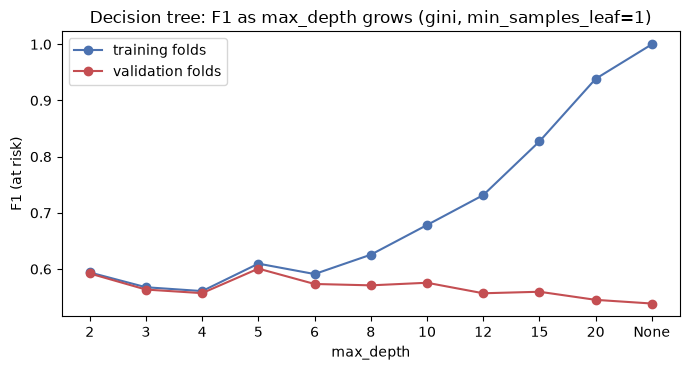

In [19]:
# Effect of max_depth (no other limit): this is the overfitting check from the Oct 20 lecture.
curve = (tree_results[(tree_results["param_clf__criterion"] == "gini")
                      & (tree_results["param_clf__min_samples_leaf"] == 1)]
         .set_index("depth").loc[DEPTH_ORDER, ["mean_train_score", "mean_test_score"]])
print(curve.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(DEPTH_ORDER, curve["mean_train_score"], marker="o", color="#4C72B0", label="training folds")
ax.plot(DEPTH_ORDER, curve["mean_test_score"], marker="o", color="#C44E52", label="validation folds")
ax.set_title("Decision tree: F1 as max_depth grows (gini, min_samples_leaf=1)")
ax.set_xlabel("max_depth"); ax.set_ylabel("F1 (at risk)"); ax.legend()
plt.tight_layout(); plt.show()

In [20]:
# Effect of min_samples_leaf at each depth (validation F1, gini).
leaf_table = (tree_results[tree_results["param_clf__criterion"] == "gini"]
              .pivot(index="depth", columns="param_clf__min_samples_leaf", values="mean_test_score")
              .loc[DEPTH_ORDER])
leaf_table.columns.name = "min_samples_leaf"
leaf_table.round(3)

min_samples_leaf,1,5,20,50,100,200
depth,,,,,,
2,0.592,0.592,0.592,0.592,0.592,0.592
3,0.564,0.564,0.564,0.564,0.564,0.564
4,0.557,0.557,0.557,0.556,0.554,0.560
5,0.601,0.601,0.602,0.603,0.602,0.603
6,0.573,0.573,0.572,0.576,0.571,0.568
8,0.571,0.568,0.569,0.572,0.580,0.572
10,0.576,0.576,0.578,0.585,0.590,0.582
12,0.557,0.560,0.576,0.587,0.590,0.580
15,0.560,0.565,0.572,0.586,0.591,0.580


In [21]:
# Part 2: for the tree, compare criterion="gini" vs criterion="entropy".
# Gini vs entropy: same settings, different splitting criterion.
crit_rows = []
for crit in ["gini", "entropy"]:
    sub = tree_results[tree_results["param_clf__criterion"] == crit]
    unlimited = sub[(sub["depth"] == "None") & (sub["param_clf__min_samples_leaf"] == 1)].iloc[0]
    best = sub.loc[sub["mean_test_score"].idxmax()]
    crit_rows.append({"criterion": crit,
                      "unlimited tree: CV F1": unlimited["mean_test_score"],
                      "best in grid: CV F1": best["mean_test_score"],
                      "best depth": best["depth"],
                      "best min_samples_leaf": best["param_clf__min_samples_leaf"]})
crit_table = pd.DataFrame(crit_rows).set_index("criterion")
display(crit_table.round(4))

wide = tree_results.pivot(index=["depth", "param_clf__min_samples_leaf"], columns="param_clf__criterion",
                          values="mean_test_score")
print("largest gap between gini and entropy across the grid:", round((wide["gini"] - wide["entropy"]).abs().max(), 4))
print("mean absolute gap:", round((wide["gini"] - wide["entropy"]).abs().mean(), 4))

,unlimited tree: CV F1,best in grid: CV F1,best depth,best min_samples_leaf
criterion,,,,
gini,0.5387,0.6032,5,50
entropy,0.5399,0.6057,5,50


largest gap between gini and entropy across the grid: 0.0132
mean absolute gap: 0.0046


**TODO (markdown):** Report the effect of the decision-tree hyperparameters, and compare gini vs entropy.

max_depth: training F1 goes towards 1.000 as depth grows, validation falls from 0.601 at depth 5 to 0.539 with no limit. This is overfitting.

min_sampels_leaf: larger leaves limit deep trees. Without depth limit, validation F1 goes from 0.539 at 1 to 0.591 at 100.

Gini vs entropy: virtually no difference. Best F1 for gini is 0.6032, while it is 0.6057 for entropy. Depth and leaf size matter more.

In [22]:
# Part 2: explore non-default hyperparameters. k-NN: n_neighbors, weights, metric.
knn_grid = {
    "clf__n_neighbors": [1, 3, 5, 11, 21, 31, 51, 71, 101, 151],
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "manhattan"],
}
knn_search = GridSearchCV(make_model(KNeighborsClassifier()), knn_grid, scoring="f1", cv=cv5, n_jobs=-1)
knn_search.fit(X_tr, y_tr)

knn_results = pd.DataFrame(knn_search.cv_results_)
print("combinations tried:", len(knn_results))
print("best CV F1:", round(knn_search.best_score_, 4), "| best parameters:", knn_search.best_params_)

knn_table = knn_results.pivot(index="param_clf__n_neighbors",
                              columns=["param_clf__metric", "param_clf__weights"], values="mean_test_score")
knn_table.index.name = "k"
knn_table.round(3)

combinations tried: 40
best CV F1: 0.5814 | best parameters: {'clf__metric': 'euclidean', 'clf__n_neighbors': 21, 'clf__weights': 'distance'}


param_clf__metric  euclidean          manhattan         
param_clf__weights   uniform distance   uniform distance
k                                                       
1                      0.538    0.538     0.539    0.539
3                      0.549    0.550     0.553    0.552
5                      0.563    0.564     0.563    0.563
11                     0.569    0.570     0.575    0.577
21                     0.579    0.581     0.572    0.573
31                     0.575    0.576     0.572    0.577
51                     0.571    0.573     0.572    0.574
71                     0.569    0.570     0.566    0.571
101                    0.562    0.565     0.565    0.568
151                    0.551    0.554     0.556    0.560

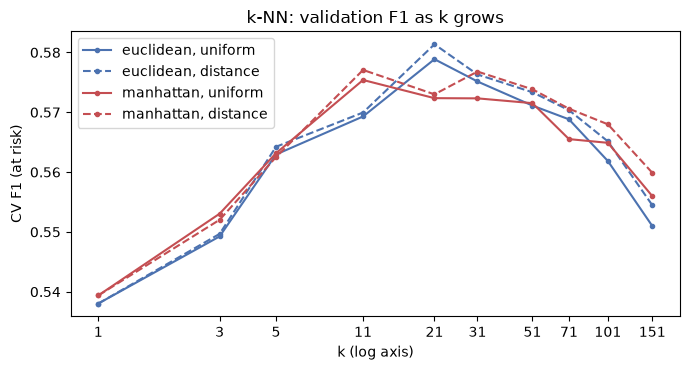

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.8))
styles = {("euclidean", "uniform"): ("#4C72B0", "-"), ("euclidean", "distance"): ("#4C72B0", "--"),
          ("manhattan", "uniform"): ("#C44E52", "-"), ("manhattan", "distance"): ("#C44E52", "--")}
for (metric, weights), (colour, line) in styles.items():
    ax.plot(knn_table.index, knn_table[(metric, weights)], color=colour, ls=line, marker="o", ms=3,
            label=f"{metric}, {weights}")
ax.set_xscale("log")
ax.set_xticks(knn_table.index); ax.set_xticklabels(knn_table.index)
ax.minorticks_off()
ax.set_title("k-NN: validation F1 as k grows"); ax.set_xlabel("k (log axis)"); ax.set_ylabel("CV F1 (at risk)")
ax.legend()
plt.tight_layout(); plt.show()

In [24]:
def strip_prefix(params):
    return {k.replace("clf__", ""): v for k, v in params.items()}

tree_params = strip_prefix(tree_search.best_params_)
knn_params  = strip_prefix(knn_search.best_params_)
print("tuned tree:", tree_params)
print("tuned k-NN:", knn_params)

tuned_tree = make_model(DecisionTreeClassifier(random_state=RANDOM_SEED, **tree_params))
tuned_knn  = make_model(KNeighborsClassifier(**knn_params))

tuned tree: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 50}
tuned k-NN: {'metric': 'euclidean', 'n_neighbors': 21, 'weights': 'distance'}


**TODO (markdown):** Report the effect of the k-NN hyperparameters, and state which settings you chose for both models.

n_neighbours: F1 goes from 0.538 at k=1 to 0.581 at k-21, falls to about 0.55 at k-151. Small k follows noise and very large k includes students who aren't similar.

weights: distances weighting allows a small imrpovement at most values of k.

metric: Euclidean and Manhattan are close.

Chosen by best CV F1: the tree with criterion="entropy", max_depth=5, min_samples_leaf=50, k-NN with n_neighbours-21, weights="distance", metric="euclidean". 


## Part 3 — Evaluation (holdout + 5-fold) and eager-vs-lazy timing

In [25]:
# Part 3: evaluate both models on the held-out test set.
test_rows, test_cms = [], {}
for name, model in [("Decision tree (defaults)", default_tree), ("k-NN (defaults, k=5)", default_knn),
                    ("Decision tree (tuned)", tuned_tree), ("k-NN (tuned)", tuned_knn)]:
    row, cm = evaluate(model, name)
    test_rows.append(row); test_cms[name] = cm

=== Decision tree (defaults) ===
confusion matrix [rows=actual 0/1, cols=pred 0/1]:
[[1971 1105]
 [1104 1322]]
accuracy  = 0.599
precision = 0.545   (positive class = at risk)
recall    = 0.545
f1        = 0.545



=== k-NN (defaults, k=5) ===
confusion matrix [rows=actual 0/1, cols=pred 0/1]:
[[2207  869]
 [1177 1249]]
accuracy  = 0.628
precision = 0.590   (positive class = at risk)
recall    = 0.515
f1        = 0.550

=== Decision tree (tuned) ===
confusion matrix [rows=actual 0/1, cols=pred 0/1]:
[[2176  900]
 [ 947 1479]]
accuracy  = 0.664
precision = 0.622   (positive class = at risk)
recall    = 0.610
f1        = 0.616



=== k-NN (tuned) ===
confusion matrix [rows=actual 0/1, cols=pred 0/1]:
[[2401  675]
 [1206 1220]]
accuracy  = 0.658
precision = 0.644   (positive class = at risk)
recall    = 0.503
f1        = 0.565



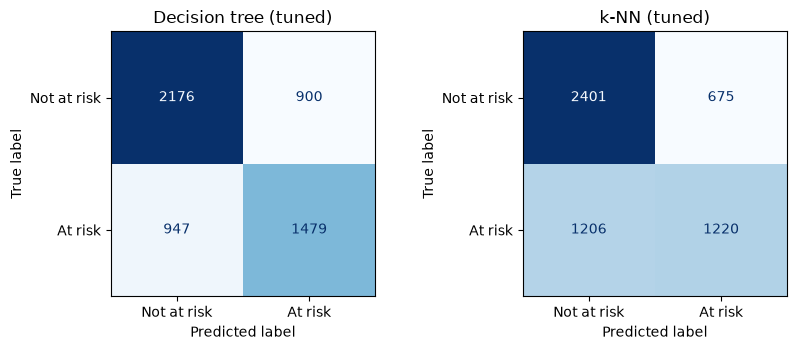

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
for ax, name in zip(axes, ["Decision tree (tuned)", "k-NN (tuned)"]):
    ConfusionMatrixDisplay(test_cms[name], display_labels=["Not at risk", "At risk"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [27]:
baseline_rows = []
for name, m in BASELINES.items():
    fitted = make_model(m).fit(X_tr, y_tr); pred = fitted.predict(X_te)
    baseline_rows.append({"model": name, "accuracy": accuracy_score(y_te, pred),
                          "precision": precision_score(y_te, pred, zero_division=0),
                          "recall": recall_score(y_te, pred, zero_division=0),
                          "f1": f1_score(y_te, pred, zero_division=0)})

test_table = pd.DataFrame(baseline_rows + test_rows).set_index("model")
test_table.round(3)

,accuracy,precision,recall,f1
model,,,,
Baseline: always 'not at risk',0.559,0.000,0.000,0.000
Baseline: always 'at risk',0.441,0.441,1.000,0.612
Baseline: random by class share,0.511,0.445,0.444,0.444
Baseline: one-split tree,0.618,0.562,0.610,0.585
Decision tree (defaults),0.599,0.545,0.545,0.545
"k-NN (defaults, k=5)",0.628,0.590,0.515,0.550
Decision tree (tuned),0.664,0.622,0.610,0.616
k-NN (tuned),0.658,0.644,0.503,0.565


In [28]:
# Part 3: 5-fold CV for both models.
fold_scores = {name: cross_validate(m, X_tr, y_tr, cv=cv5, scoring=SCORING, n_jobs=-1)
               for name, m in [("Decision tree (tuned)", tuned_tree), ("k-NN (tuned)", tuned_knn)]}

cv_table = pd.DataFrame({
    name: {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std(ddof=1):.3f}" for m in SCORING}
    for name, s in fold_scores.items()}).T
display(cv_table)

# Paired comparison on the same folds (Oct 15 lecture): difference in F1, fold by fold.
from scipy import stats
d = fold_scores["Decision tree (tuned)"]["test_f1"] - fold_scores["k-NN (tuned)"]["test_f1"]
half_width = stats.t.ppf(0.975, df=len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
print("fold differences (tree - k-NN):", np.round(d, 4))
print(f"mean difference = {d.mean():.4f}, 95% interval = [{d.mean() - half_width:.4f}, {d.mean() + half_width:.4f}]")

,accuracy,precision,recall,f1
Decision tree (tuned),0.662 ± 0.004,0.625 ± 0.016,0.590 ± 0.048,0.606 ± 0.020
k-NN (tuned),0.668 ± 0.007,0.655 ± 0.011,0.523 ± 0.011,0.581 ± 0.009


fold differences (tree - k-NN): [ 0.0342  0.0446  0.024  -0.0102  0.0291]
mean difference = 0.0243, 95% interval = [-0.0015, 0.0502]


**TODO (markdown):** Discuss the holdout and 5-fold results for both models.

Decision tree (test): accuracy 0.664, precision 0.622, recall 0.610, F1 0.616.
k-NN (test): accuracy 0.658, precision 0.644, recall 0.503, F1 0.565.

Confusion matrices: the tree missed 947 at-risk students with 900 false alarms. k-NN missed 1206 with 675 false alarms.

5-fold CV: F1 is 0.606 ± 0.020 for the tree, 0.581 ± 0.009 for k-NN. F1 difference is not clear, as its 95% interval [-0.002, 0.050] includes zero.

Overall, both beat the 0.559 accuracy baseline by about 10 percentage points. However, neither clearly beat the always-at-risk on F1 (0.612).



In [29]:
# Part 3: TIME them (eager vs lazy).
import pickle
import time
from threadpoolctl import threadpool_limits

# Time the classifiers alone: the features are already transformed, so shared preprocessing can't blur the result.
fitted_prep = build_preprocessor().fit(X_tr)
Xt_tr, Xt_te = fitted_prep.transform(X_tr), fitted_prep.transform(X_te)
y_tr_arr = y_tr.to_numpy()

def timed(clf, repeats=7):
    fit_times, predict_times = [], []
    with threadpool_limits(limits=1):       # one thread, so the two models compete fairly
        for _ in range(repeats):
            m = clone(clf)
            t0 = time.perf_counter(); m.fit(Xt_tr, y_tr_arr); fit_times.append(time.perf_counter() - t0)
            t0 = time.perf_counter(); m.predict(Xt_te);       predict_times.append(time.perf_counter() - t0)
    return m, np.median(fit_times), np.median(predict_times)

TIMED = {"Decision tree (defaults)": (DecisionTreeClassifier(random_state=RANDOM_SEED), 7),
         "Decision tree (tuned)": (DecisionTreeClassifier(random_state=RANDOM_SEED, **tree_params), 7),
         "k-NN (defaults, k=5)": (KNeighborsClassifier(), 7),
         "k-NN (tuned)": (KNeighborsClassifier(**knn_params), 7),
         "k-NN (tuned, forced KD-tree)": (KNeighborsClassifier(algorithm="kd_tree", **knn_params), 3)}

timing_rows, fitted_clfs = [], {}
for name, (clf, repeats) in TIMED.items():
    m, fit_s, predict_s = timed(clf, repeats)
    fitted_clfs[name] = m
    timing_rows.append({"model": name, "train (ms)": fit_s * 1000, "predict test set (ms)": predict_s * 1000,
                        "predict per student (µs)": predict_s / len(Xt_te) * 1e6,
                        "stored size (KB)": len(pickle.dumps(m)) / 1024})
timing_table = pd.DataFrame(timing_rows).set_index("model")
display(timing_table.round(1))

,train (ms),predict test set (ms),predict per student (µs),stored size (KB)
model,,,,
Decision tree (defaults),69.6,0.8,0.1,895.6
Decision tree (tuned),21.1,0.3,0.1,6.0
"k-NN (defaults, k=5)",0.6,194.4,35.3,5846.5
k-NN (tuned),0.6,210.8,38.3,5846.5
"k-NN (tuned, forced KD-tree)",8.2,809.0,147.0,6578.4


In [30]:
# What does each fitted model actually store?
t = fitted_clfs["Decision tree (tuned)"].tree_
t_default = fitted_clfs["Decision tree (defaults)"].tree_
print(f"default tree: {t_default.node_count:,} nodes, depth {t_default.max_depth}, {t_default.n_leaves:,} leaves")
print(f"tuned tree:   {t.node_count:,} nodes, depth {t.max_depth}, {t.n_leaves:,} leaves")

k = fitted_clfs["k-NN (tuned)"]
print(f"\nk-NN stored training matrix: {k._fit_X.shape[0]:,} rows x {k._fit_X.shape[1]} columns "
      f"= {k._fit_X.nbytes / 1024:,.0f} KB, plus {k._y.nbytes / 1024:,.0f} KB of labels")
print("search method sklearn chose for k-NN (algorithm='auto'):", k._fit_method)
print("search method for default k-NN:", fitted_clfs["k-NN (defaults, k=5)"]._fit_method)

default tree: 11,449 nodes, depth 39, 5,725 leaves
tuned tree:   63 nodes, depth 5, 32 leaves

k-NN stored training matrix: 22,008 rows x 33 columns = 5,674 KB, plus 172 KB of labels
search method sklearn chose for k-NN (algorithm='auto'): brute
search method for default k-NN: brute


**TODO (markdown):** Discuss (markdown): training time, prediction time, memory. Why are they opposite?

Training time: around 21ms for the tree and 0.6ms for k-NN.

Prediction time (5502 students): around 0.3ms for the tree and 210ms for k-NN.

Memory: tree stores 63 nodes (around 6KB), k-NN stores all 22,008 training rows (around 5850 KB).

The reason the training times are opposide is because the tree does the work during training then follows one path. Meanwhile, k-NN does virtually nothing during training then compares each query to every stored row.

Time complexites for the tree is O(d nlogn), prediction is O(depth) per query. Then, for k-NN, training is O(1) beyond the storing of data, prediction is O(nd).


In [31]:
# Extra check: what would the whole-course features have done?
WHOLE_COURSE = ["total_clicks", "active_days"]
whole_course_prep = build_preprocessor(log_numeric=LOG_NUMERIC + ["total_clicks"], numeric=NUMERIC + ["active_days"])

everyone = analysis.copy()
everyone["at_risk"] = everyone["final_result"].isin(AT_RISK).astype(int)

SCENARIOS = [("Reported: day-30 features, still enrolled", df, FEATURES, None),
             ("Day-30 features, including students who already left", everyone, FEATURES, None),
             ("Whole-course features, still enrolled", df, FEATURES + WHOLE_COURSE, whole_course_prep),
             ("Whole-course features, including students who already left", everyone, FEATURES + WHOLE_COURSE, whole_course_prep)]

leak_rows = []
for label, data, cols, prep in SCENARIOS:
    for model_name, clf in [("tree", DecisionTreeClassifier(random_state=RANDOM_SEED, **tree_params)),
                            ("k-NN", KNeighborsClassifier(**knn_params))]:
        row = cv_summary(make_model(clf, prep), model_name, X_=data[cols], y_=data["at_risk"])
        leak_rows.append({"scenario": label, "model": model_name, "accuracy": row["accuracy"],
                          "recall": row["recall"], "f1": row["f1"]})
leak_table = pd.DataFrame(leak_rows).pivot(index="scenario", columns="model", values=["accuracy", "recall", "f1"])
leak_table.loc[[s[0] for s in SCENARIOS]].round(3)

accuracy        recall  \
model                                                  k-NN   tree   k-NN   
scenario                                                                    
Reported: day-30 features, still enrolled             0.665  0.662  0.519   
Day-30 features, including students who already...    0.706  0.700  0.677   
Whole-course features, still enrolled                 0.814  0.839  0.714   
Whole-course features, including students who a...    0.837  0.865  0.810   

                                                              f1         
model                                                tree   k-NN   tree  
scenario                                                                 
Reported: day-30 features, still enrolled           0.586  0.578  0.604  
Day-30 features, including students who already...  0.712  0.709  0.715  
Whole-course features, still enrolled               0.718  0.772  0.798  
Whole-course features, including students who a...  0.829  0.840  0.867

In [32]:
# Extra check: the same student can appear on both sides of a random split.
from sklearn.model_selection import StratifiedGroupKFold

groups = df["id_student"]
print("rows:", len(df), "| distinct students:", groups.nunique())
shared = set(groups.loc[X_tr.index]) & set(groups.loc[X_te.index])
print("test rows whose student also appears in the training set:", int(groups.loc[X_te.index].isin(shared).sum()),
      f"({groups.loc[X_te.index].isin(shared).mean():.1%} of the test set)")

group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
split_rows = []
for model_name, m in [("tree", tuned_tree), ("k-NN", tuned_knn)]:
    plain = cross_validate(m, X, y, cv=cv5, scoring="f1", n_jobs=-1)["test_score"]
    grouped = cross_validate(m, X, y, cv=group_cv, groups=groups, scoring="f1", n_jobs=-1)["test_score"]
    split_rows.append({"model": model_name, "StratifiedKFold F1": plain.mean(), "StratifiedGroupKFold F1": grouped.mean(),
                       "difference": plain.mean() - grouped.mean()})
pd.DataFrame(split_rows).set_index("model").round(4)

rows: 27510 | distinct students: 24822
test rows whose student also appears in the training set: 875 (15.9% of the test set)


,StratifiedKFold F1,StratifiedGroupKFold F1,difference
model,,,
tree,0.6042,0.5999,0.0043
k-NN,0.5779,0.5782,-0.0003


**TODO (markdown):** Discuss the extra checks (leakage and repeat students) and the limitations of this analysis.

Leakage: using whole-course features and keeping students who had already left brings the tree F1 from 0.604 to 0.867. Those scores couldn't be achived on day 30, so the lower ones are reported.

Repeat students: 15.9% of test rows have a student who is also in training. Keeping each student from one changed F1 by 0.004 at most.

Limitations: the signal is modest and day 30 is a judgement call. The data comes from 1 univeersity, while clicks measure activity and not the understanding of the content. Also, the model doesn't cover students who left before day 30.

## Part 4 — Feature importance

encoded columns the tree actually used: 10 of 33

importance by original feature (one-hot columns summed):
early_active_days       0.5305
code_module             0.2308
highest_education       0.0996
early_clicks            0.0963
imd_band                0.0220
num_of_prev_attempts    0.0123
date_registration       0.0084
age_band                0.0000
disability              0.0000
gender                  0.0000
region                  0.0000
studied_credits         0.0000

top encoded columns:
num__early_active_days       0.5305
nom__code_module_BBB         0.1093
nom__code_module_GGG         0.1078
ord__highest_education       0.0996
log_num__early_clicks        0.0963
ord__imd_band                0.0220
num__num_of_prev_attempts    0.0123
nom__code_module_DDD         0.0111
num__date_registration       0.0084
nom__code_module_FFF         0.0027


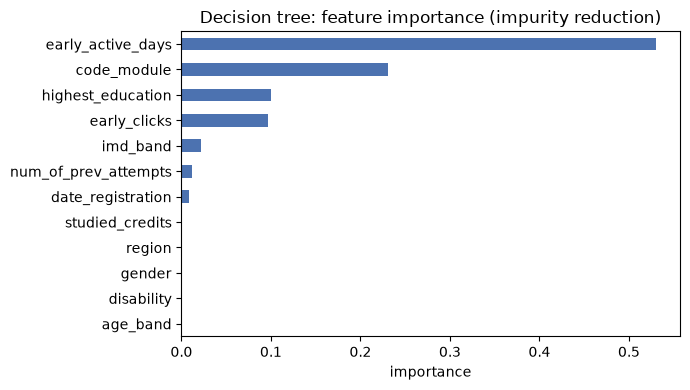

In [33]:
# Part 4a: decision-tree feature importance.
tuned_tree.fit(X_tr, y_tr)
encoded_names = tuned_tree.named_steps["prep"].get_feature_names_out()
encoded_imp = pd.Series(tuned_tree.named_steps["clf"].feature_importances_, index=encoded_names)

def original_feature(encoded):
    """Map an encoded column name back to the original feature it came from."""
    bare = encoded.split("__", 1)[1].replace("missingindicator_", "")
    return next(c for c in FEATURES if bare == c or bare.startswith(c + "_"))

tree_imp = encoded_imp.groupby(original_feature).sum().sort_values(ascending=False)
print("encoded columns the tree actually used:", int((encoded_imp > 0).sum()), "of", len(encoded_imp))
print("\nimportance by original feature (one-hot columns summed):")
print(tree_imp.round(4).to_string())
print("\ntop encoded columns:")
print(encoded_imp.sort_values(ascending=False).head(10).round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
tree_imp.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Decision tree: feature importance (impurity reduction)"); ax.set_xlabel("importance")
plt.tight_layout(); plt.show()

**TODO (markdown):** Which features matter most? Do they match your expectations?

*Your discussion here...*

In [34]:
# Part 4b: k-NN has no native importance -> use permutation importance.
from sklearn.inspection import permutation_importance

tuned_knn.fit(X_tr, y_tr)
PERM = dict(X=X_te, y=y_te, scoring="f1", n_repeats=10, random_state=RANDOM_SEED, n_jobs=-1)

knn_perm  = permutation_importance(tuned_knn, **PERM)
tree_perm = permutation_importance(tuned_tree, **PERM)

perm_table = pd.DataFrame({"k-NN drop in F1": knn_perm.importances_mean, "k-NN sd": knn_perm.importances_std,
                           "tree drop in F1": tree_perm.importances_mean, "tree sd": tree_perm.importances_std},
                          index=X_te.columns).sort_values("k-NN drop in F1", ascending=False)
perm_table.round(4)

,k-NN drop in F1,k-NN sd,tree drop in F1,tree sd
early_active_days,0.0435,0.0047,0.1130,0.0099
early_clicks,0.0284,0.0065,0.0036,0.0007
highest_education,0.0171,0.0071,0.0270,0.0061
imd_band,0.0103,0.0063,0.0000,0.0000
code_module,0.0055,0.0042,0.0396,0.0040
gender,0.0014,0.0036,0.0000,0.0000
num_of_prev_attempts,0.0011,0.0033,0.0014,0.0008
disability,0.0004,0.0019,0.0000,0.0000
studied_credits,0.0004,0.0037,0.0000,0.0000
age_band,-0.0007,0.0026,0.0000,0.0000


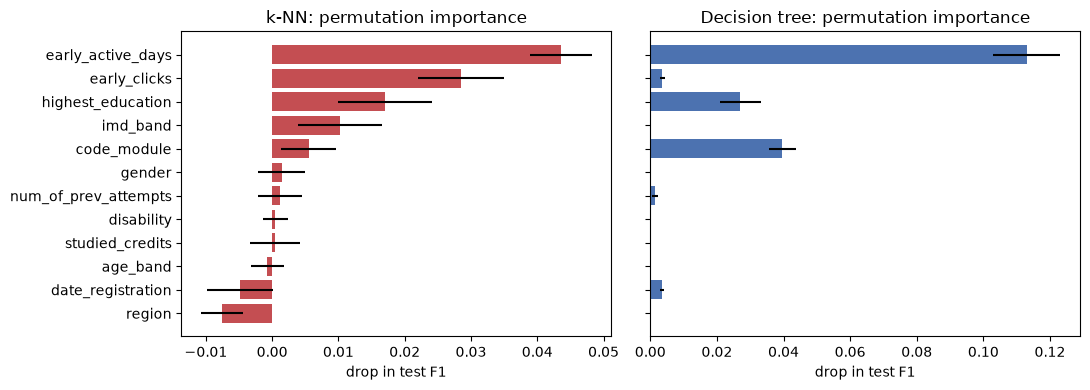

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
order = perm_table["k-NN drop in F1"].sort_values().index
axes[0].barh(order, perm_table.loc[order, "k-NN drop in F1"], xerr=perm_table.loc[order, "k-NN sd"], color="#C44E52")
axes[0].set_title("k-NN: permutation importance"); axes[0].set_xlabel("drop in test F1")
axes[1].barh(order, perm_table.loc[order, "tree drop in F1"], xerr=perm_table.loc[order, "tree sd"], color="#4C72B0")
axes[1].set_title("Decision tree: permutation importance"); axes[1].set_xlabel("drop in test F1")
plt.tight_layout(); plt.show()

In [36]:
importance_scores = pd.DataFrame({"tree impurity": tree_imp,
                                  "tree permutation": perm_table["tree drop in F1"],
                                  "k-NN permutation": perm_table["k-NN drop in F1"]})
ranks = importance_scores.rank(ascending=False, method="min").astype(int)   # ties share the best rank
display(ranks.sort_values(["tree impurity", "k-NN permutation"]))

for a, b in [("tree impurity", "k-NN permutation"), ("tree permutation", "k-NN permutation"),
             ("tree impurity", "tree permutation")]:
    rho = stats.spearmanr(importance_scores[a], importance_scores[b]).statistic
    print(f"Spearman rank correlation, {a} vs {b}: {rho:.3f}")

print("\ncorrelation of early_clicks and early_active_days:",
      round(df["early_clicks"].corr(df["early_active_days"], method="spearman"), 3))

,tree impurity,tree permutation,k-NN permutation
early_active_days,1,1,1
code_module,2,2,5
highest_education,3,3,3
early_clicks,4,4,2
imd_band,5,7,4
num_of_prev_attempts,6,6,7
date_registration,7,5,11
gender,8,7,6
disability,8,7,8
studied_credits,8,7,9


Spearman rank correlation, tree impurity vs k-NN permutation: 0.798
Spearman rank correlation, tree permutation vs k-NN permutation: 0.623
Spearman rank correlation, tree impurity vs tree permutation: 0.902

correlation of early_clicks and early_active_days: 0.886


**TODO (markdown):** Explain why k-NN needs permutation importance, and compare its ranking to the tree's.

*Your discussion here...*

**TODO (markdown):** Discuss the challenge of determining feature importance in a lazy learner, and how understanding feature importance improves interpretability and real-world decision-making.

*Your discussion here...*

## Part 5 — Eager vs. lazy learning (discussion)

**TODO (markdown):** Explain the conceptual difference between eager and lazy learners; how decision trees
and k-NN differ in training vs prediction; and the trade-offs (when would you choose each?). Back it up
with your timing numbers from Part 3.

*Your discussion here...*

## Part 6 — Reproducibility

- The random seed is set at the top (`RANDOM_SEED`).
- Before submitting: **Kernel → Restart & Run All**.

## Submission checklist
- [ ] Exploration done (class distribution, feature types, distribution plots)
- [ ] Both models trained: defaults + explored hyperparameters; tree gini vs entropy
- [ ] Confusion matrix + accuracy/precision/recall/F1 for both (+ 5-fold CV)
- [ ] Training/prediction time + memory discussed (eager vs lazy)
- [ ] Decision-tree importances + k-NN permutation importance, with discussion
- [ ] Eager vs lazy written discussion
- [ ] Runs top-to-bottom on a clean kernel; renamed `a2_lastname.ipynb`
- [ ] AI use disclosed

## Generative-AI disclosure

**TODO (markdown):** Disclose how you used generative-AI tools.

*Your discussion here...*